In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('/blue/bsc4452/share/Class_Files/data/world.sqlite')

In [2]:
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
pd.read_sql_query("SELECT * FROM country LIMIT 5;", conn)

,Code,Name,Continent,Region,SurfaceArea,IndepYear,Population,LifeExpectancy,GNP,GNPOld,LocalName,GovernmentForm,HeadOfState,Capital,Code2
0,ABW,Aruba,North America,Caribbean,193.0,NaN,103000,78.4,828.0,793.0,Aruba,Nonmetropolitan Territory of The Netherlands,Beatrix,129,AW
1,AFG,Afghanistan,Asia,Southern and Central Asia,652090.0,1919.0,22720000,45.9,5976.0,NaN,Afganistan/Afqanestan,Islamic Emirate,Mohammad Omar,1,AF
2,AGO,Angola,Africa,Central Africa,1246700.0,1975.0,12878000,38.3,6648.0,7984.0,Angola,Republic,Jos� Eduardo dos Santos,56,AO
3,AIA,Anguilla,North America,Caribbean,96.0,NaN,8000,76.1,63.2,NaN,Anguilla,Dependent Territory of the UK,Elisabeth II,62,AI
4,ALB,Albania,Europe,Southern Europe,28748.0,1912.0,3401200,71.6,3205.0,2500.0,Shqip�ria,Republic,Rexhep Mejdani,34,AL


In [6]:
# Question 1
pd.read_sql_query("""
    SELECT Name, IndepYear
    FROM country
    ORDER BY IndepYear DESC
    LIMIT 1;
""", conn)
## Answer: Palau, Independent Year 1994

,Name,IndepYear
0,Palau,1994


In [10]:
# Question 2
## Choose country: Montenegro
conn.execute("""
    INSERT INTO country (Code, Name, Continent, SurfaceArea, IndepYear, Population)
    VALUES ('MNE', 'Montenegro', 'Europe', 13883, 2006, 622902);
""")
conn.commit()

OperationalError: attempt to write a readonly database

In [12]:
# Question 3
conn.execute("""
    INSERT INTO city (Name, CountryCode, District, Population)
    VALUES ('Podgorica', 'MNE', 'Podgorica', 179505),
           ('Nikšić', 'MNE', 'Nikšić', 65705);
""")
conn.commit()

OperationalError: attempt to write a readonly database

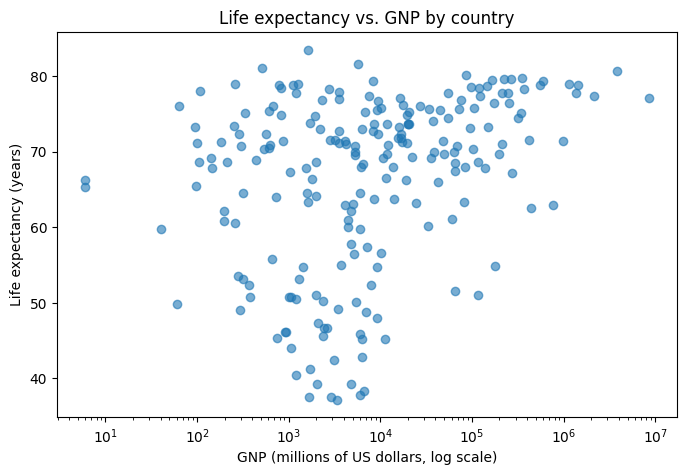

In [13]:
# Question 4
import matplotlib.pyplot as plt

df = pd.read_sql_query("""
    SELECT Name, GNP, LifeExpectancy
    FROM country
    WHERE LifeExpectancy IS NOT NULL AND GNP > 0;
""", conn)

plt.figure(figsize=(8, 5))
plt.scatter(df['GNP'], df['LifeExpectancy'], alpha=0.6)
plt.xscale('log')
plt.xlabel('GNP (millions of US dollars, log scale)')
plt.ylabel('Life expectancy (years)')
plt.title('Life expectancy vs. GNP by country')
plt.show()

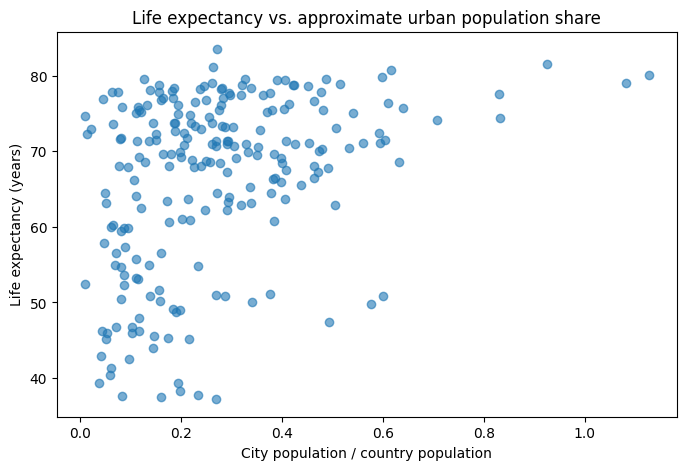

In [15]:
# Question 5
df = pd.read_sql_query("""
    SELECT country.Name,
           country.LifeExpectancy,
           SUM(city.Population) * 1.0 / country.Population AS UrbanRatio
    FROM country
    JOIN city ON city.CountryCode = country.Code
    WHERE country.LifeExpectancy IS NOT NULL
      AND country.Population > 0
    GROUP BY country.Code;
""", conn)

plt.figure(figsize=(8, 5))
plt.scatter(df['UrbanRatio'], df['LifeExpectancy'], alpha=0.6)
plt.xlabel('City population / country population')
plt.ylabel('Life expectancy (years)')
plt.title('Life expectancy vs. approximate urban population share')
plt.show()